<a href="https://colab.research.google.com/github/Chaki34/SaiKet_Systems_Data_Science_Internship/blob/main/Task_2_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Task 2: Exploratory Data Analysis (EDA)

## Project: Customer Churn Analysis and Prediction

**Organization:** SaiKet Systems  
**Internship Domain:** Data Science  
**Task:** Exploratory Data Analysis

### Objective

The objective of this task is to perform Exploratory Data Analysis on the Telco Customer Churn dataset to understand customer behavior and identify patterns associated with customer churn.

This analysis focuses on calculating the overall churn rate, exploring customer demographics, analyzing tenure distribution, and investigating churn across different contract types and payment methods.

### Dataset
Telco Customer Churn Dataset

### Tools and Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn


In [ ]:

# Step 1: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

# Display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization configuration
sns.set_theme(style="whitegrid", palette="Set2")

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

print("All required libraries imported successfully!")


All required libraries imported successfully!


In [ ]:

# Step 2: Load Dataset

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

print("\nDataset Shape:", df.shape)

display(df.head())


Saving Telco_Customer_Churn_Dataset  (3) (1).csv to Telco_Customer_Churn_Dataset  (3) (1) (1).csv
Dataset loaded successfully!

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:

# Step 3: Inspect Dataset Information

print("Dataset Information:")
df.info()

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe(include='all').T)

print("\nDuplicate Records:", df.duplicated().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Duplicate Records: 0


In [ ]:

# Step 4: Basic Data Cleaning

# Create a working copy
df = df.copy()

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Remove leading and trailing spaces from text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Convert TotalCharges into numeric format
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Handle missing TotalCharges
# In this dataset, missing TotalCharges values
# correspond to customers with zero tenure.
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Verify important columns
required_columns = [
    'gender',
    'Partner',
    'Dependents',
    'tenure',
    'Contract',
    'PaymentMethod',
    'Churn'
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Ensure tenure is numeric
df['tenure'] = pd.to_numeric(df['tenure'], errors='coerce')

# Remove records with missing values in essential EDA columns
df = df.dropna(subset=required_columns)

# Validate churn labels
df = df[df['Churn'].isin(['Yes', 'No'])]

print("Data cleaning completed successfully!")
print("\nCleaned Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df[required_columns].isnull().sum())


Data cleaning completed successfully!

Cleaned Dataset Shape: (7043, 21)

Missing Values:
gender           0
Partner          0
Dependents       0
tenure           0
Contract         0
PaymentMethod    0
Churn            0
dtype: int64


In [ ]:

# Step 5: Calculate Overall Customer Churn Rate

churn_counts = df['Churn'].value_counts()

total_customers = len(df)

churned_customers = churn_counts.get('Yes', 0)
retained_customers = churn_counts.get('No', 0)

churn_rate = (churned_customers / total_customers) * 100
retention_rate = (retained_customers / total_customers) * 100

print("CUSTOMER CHURN ANALYSIS")
print("-" * 40)

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)

print(f"\nOverall Churn Rate: {churn_rate:.2f}%")
print(f"Customer Retention Rate: {retention_rate:.2f}%")


CUSTOMER CHURN ANALYSIS
----------------------------------------
Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174

Overall Churn Rate: 26.54%
Customer Retention Rate: 73.46%


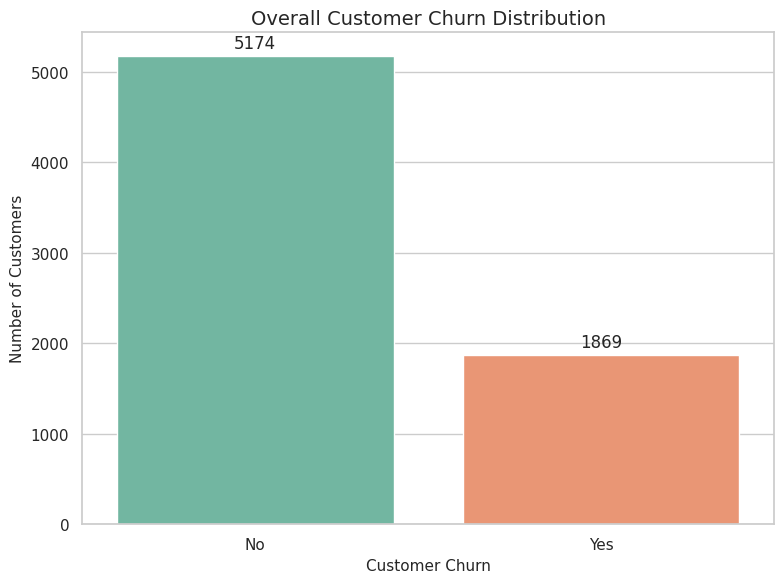

In [ ]:

# Step 6: Visualize Overall Churn Distribution

plt.figure(figsize=(8, 6))

ax = sns.countplot(
    data=df,
    x='Churn',
    hue='Churn',
    order=['No', 'Yes'],
    legend=False
)

plt.title('Overall Customer Churn Distribution')
plt.xlabel('Customer Churn')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


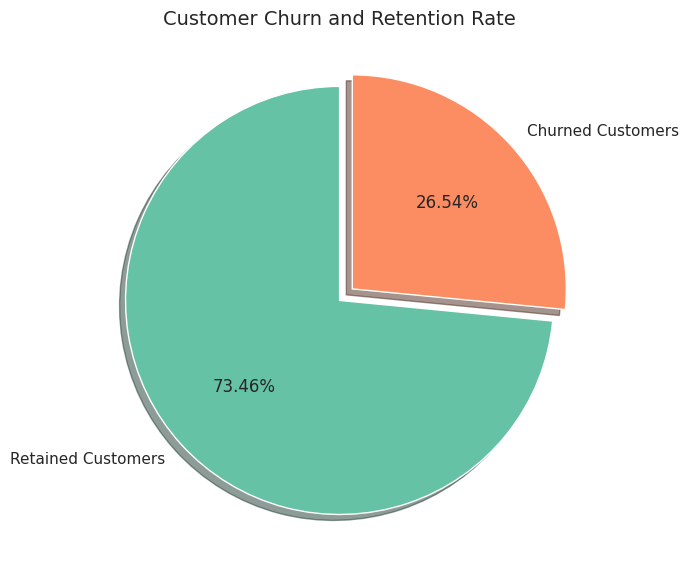

In [ ]:

# Step 7: Churn Rate Pie Chart

plt.figure(figsize=(7, 7))

plt.pie(
    [retained_customers, churned_customers],
    labels=['Retained Customers', 'Churned Customers'],
    autopct='%1.2f%%',
    startangle=90,
    explode=(0, 0.08),
    shadow=True
)

plt.title('Customer Churn and Retention Rate')
plt.tight_layout()
plt.show()


In [ ]:

# Step 8: Customer Distribution by Gender

gender_distribution = df['gender'].value_counts()

print("Customer Distribution by Gender:")
display(gender_distribution.to_frame(name='Customer Count'))

# Gender-wise churn counts
gender_churn = pd.crosstab(
    df['gender'],
    df['Churn']
)

print("\nGender-wise Churn Distribution:")
display(gender_churn)

# Gender-wise churn rate
gender_churn_rate = pd.crosstab(
    df['gender'],
    df['Churn'],
    normalize='index'
) * 100

print("\nGender-wise Churn Percentage:")
display(gender_churn_rate.round(2))


Customer Distribution by Gender:


,Customer Count
gender,
Male,3555
Female,3488



Gender-wise Churn Distribution:


Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930



Gender-wise Churn Percentage:


Churn,No,Yes
gender,,
Female,73.08,26.92
Male,73.84,26.16


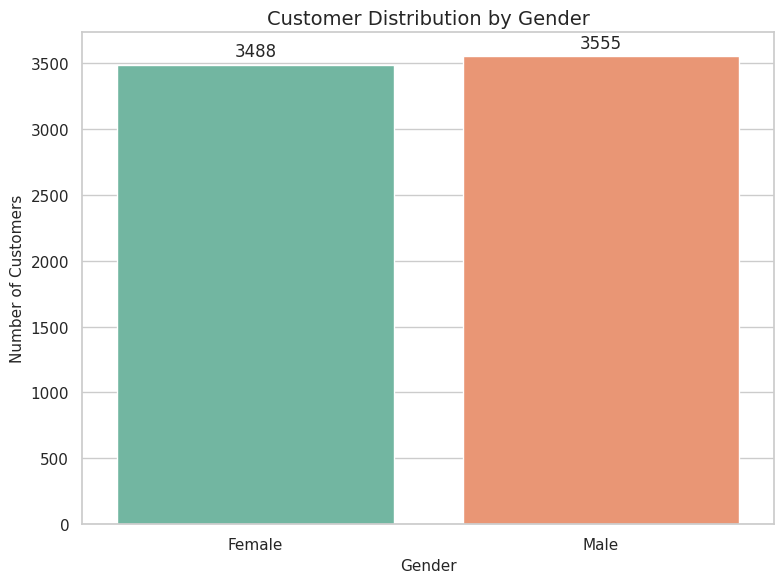

In [ ]:

# Step 9: Visualize Gender Distribution

plt.figure(figsize=(8, 6))

ax = sns.countplot(
    data=df,
    x='gender',
    hue='gender',
    legend=False
)

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


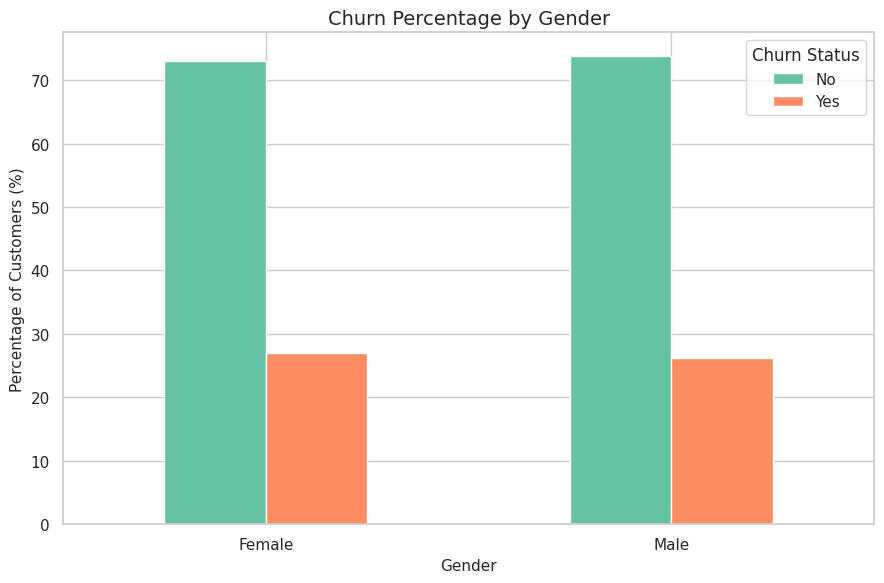

In [ ]:

# Step 10: Gender-wise Churn Rate Visualization

gender_churn_rate.plot(
    kind='bar',
    figsize=(9, 6),
    stacked=False
)

plt.title('Churn Percentage by Gender')
plt.xlabel('Gender')
plt.ylabel('Percentage of Customers (%)')

plt.xticks(rotation=0)
plt.legend(title='Churn Status')

plt.tight_layout()
plt.show()


In [ ]:

# Step 11: Partner and Dependent Status Analysis

# Partner distribution
partner_distribution = df['Partner'].value_counts()

print("Partner Distribution:")
display(partner_distribution.to_frame(name='Customer Count'))

# Dependent distribution
dependent_distribution = df['Dependents'].value_counts()

print("\nDependent Distribution:")
display(dependent_distribution.to_frame(name='Customer Count'))

# Churn based on partner status
partner_churn = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

print("\nPartner-wise Churn Percentage:")
display(partner_churn.round(2))

# Churn based on dependent status
dependent_churn = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

print("\nDependent-wise Churn Percentage:")
display(dependent_churn.round(2))


Partner Distribution:


,Customer Count
Partner,
No,3641
Yes,3402



Dependent Distribution:


,Customer Count
Dependents,
No,4933
Yes,2110



Partner-wise Churn Percentage:


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66



Dependent-wise Churn Percentage:


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


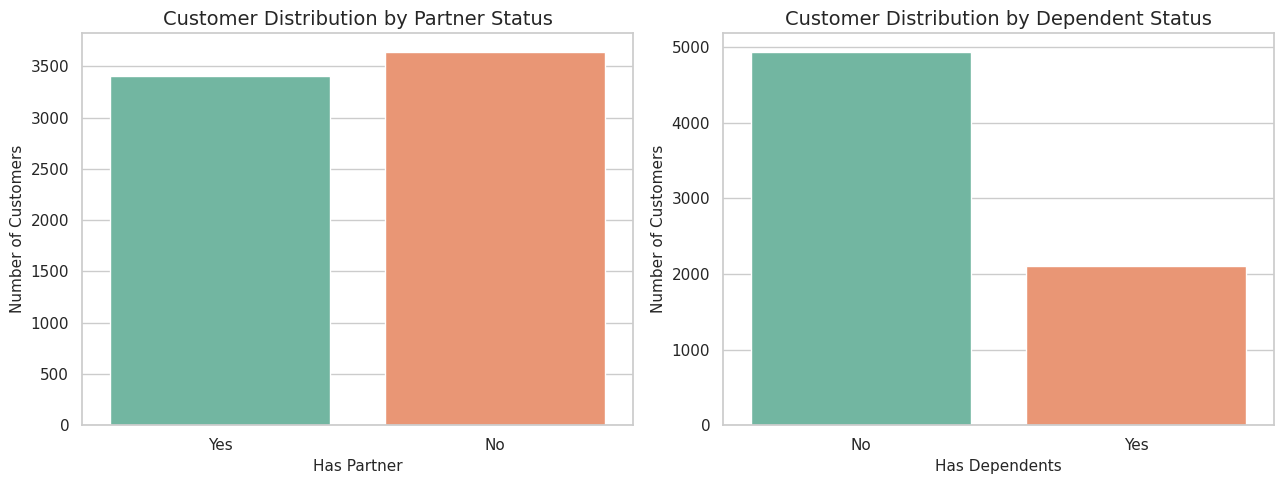

In [ ]:

# Step 12: Visualize Partner and Dependent Distribution

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=df,
    x='Partner',
    hue='Partner',
    legend=False,
    ax=axes[0]
)

axes[0].set_title('Customer Distribution by Partner Status')
axes[0].set_xlabel('Has Partner')
axes[0].set_ylabel('Number of Customers')

sns.countplot(
    data=df,
    x='Dependents',
    hue='Dependents',
    legend=False,
    ax=axes[1]
)

axes[1].set_title('Customer Distribution by Dependent Status')
axes[1].set_xlabel('Has Dependents')
axes[1].set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()


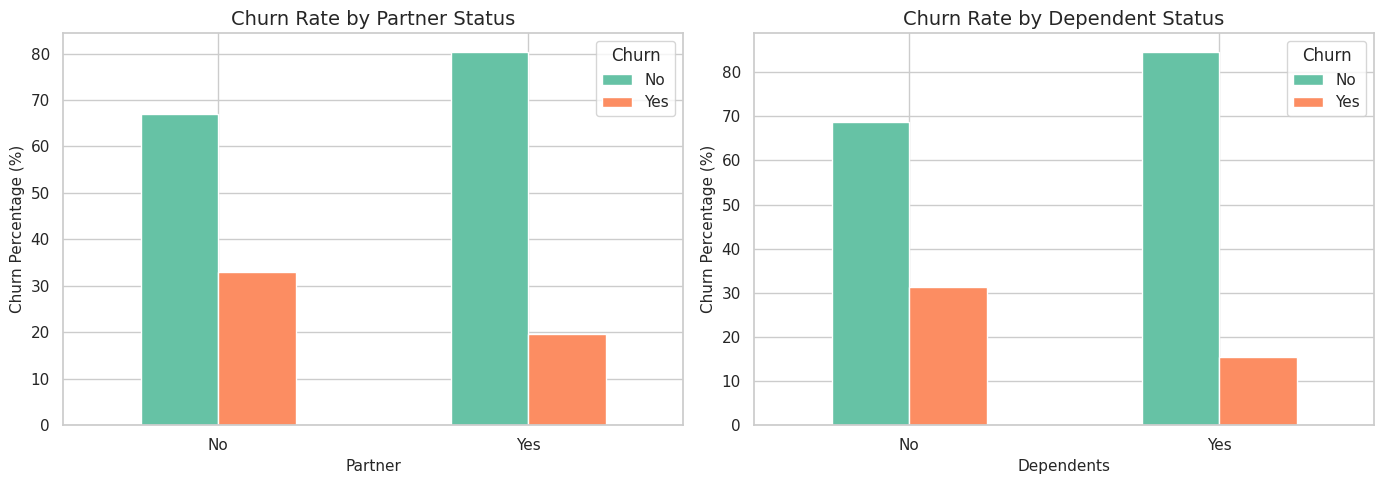

In [ ]:

# Step 13: Compare Churn by Partner and Dependent Status

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

partner_churn.plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Churn Rate by Partner Status')
axes[0].set_xlabel('Partner')
axes[0].set_ylabel('Churn Percentage (%)')
axes[0].tick_params(axis='x', rotation=0)

dependent_churn.plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Churn Rate by Dependent Status')
axes[1].set_xlabel('Dependents')
axes[1].set_ylabel('Churn Percentage (%)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


In [ ]:

# Step 14: Analyze Customer Tenure

print("CUSTOMER TENURE ANALYSIS")
print("-" * 40)

print("Average Tenure:", round(df['tenure'].mean(), 2), "months")

print("Median Tenure:", round(df['tenure'].median(), 2), "months")

print("Minimum Tenure:", df['tenure'].min(), "months")

print("Maximum Tenure:", df['tenure'].max(), "months")

print("\nTenure Statistical Summary:")
display(df['tenure'].describe())


CUSTOMER TENURE ANALYSIS
----------------------------------------
Average Tenure: 32.37 months
Median Tenure: 29.0 months
Minimum Tenure: 0 months
Maximum Tenure: 72 months

Tenure Statistical Summary:


,tenure
count,7043.000000
mean,32.371149
std,24.559481
min,0.000000
25%,9.000000
50%,29.000000
75%,55.000000
max,72.000000


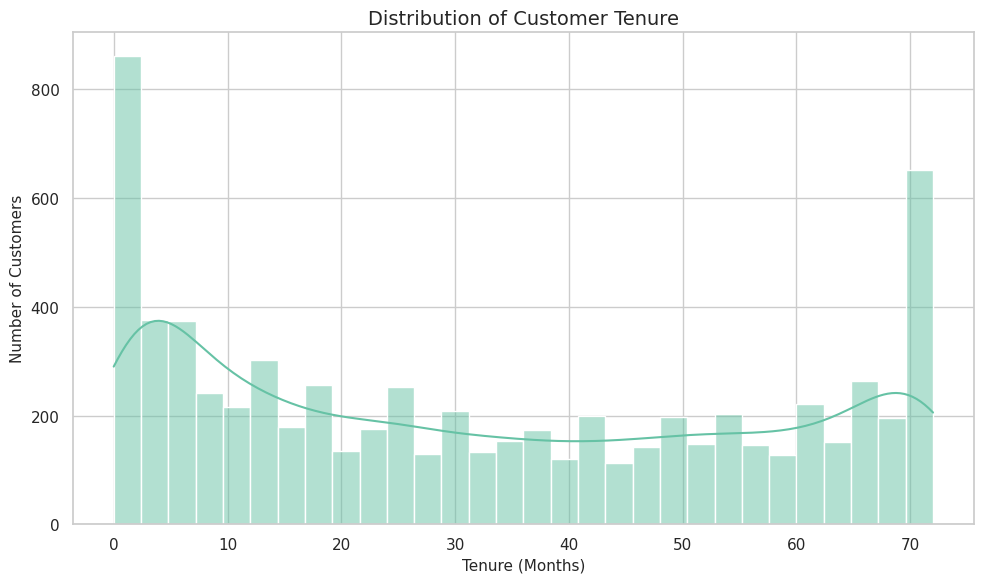

In [ ]:

# Step 15: Visualize Customer Tenure Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='tenure',
    bins=30,
    kde=True
)

plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


In [ ]:

# Step 17: Create Tenure Groups and Analyze Churn

bins = [-1, 12, 24, 48, 60, 72]
labels = [
    '0-12 Months',
    '13-24 Months',
    '25-48 Months',
    '49-60 Months',
    '61-72 Months'
]

df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels
)

tenure_analysis = df.groupby(
    'TenureGroup',
    observed=False
).agg(
    Total_Customers=('Churn', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
)

tenure_analysis['Churn_Rate'] = (
    tenure_analysis['Churned_Customers'] /
    tenure_analysis['Total_Customers'] * 100
)

print("Tenure Group-wise Churn Analysis:")
display(tenure_analysis.round(2))


Tenure Group-wise Churn Analysis:


,Total_Customers,Churned_Customers,Churn_Rate
TenureGroup,,,
0-12 Months,2186,1037,47.44
13-24 Months,1024,294,28.71
25-48 Months,1594,325,20.39
49-60 Months,832,120,14.42
61-72 Months,1407,93,6.61


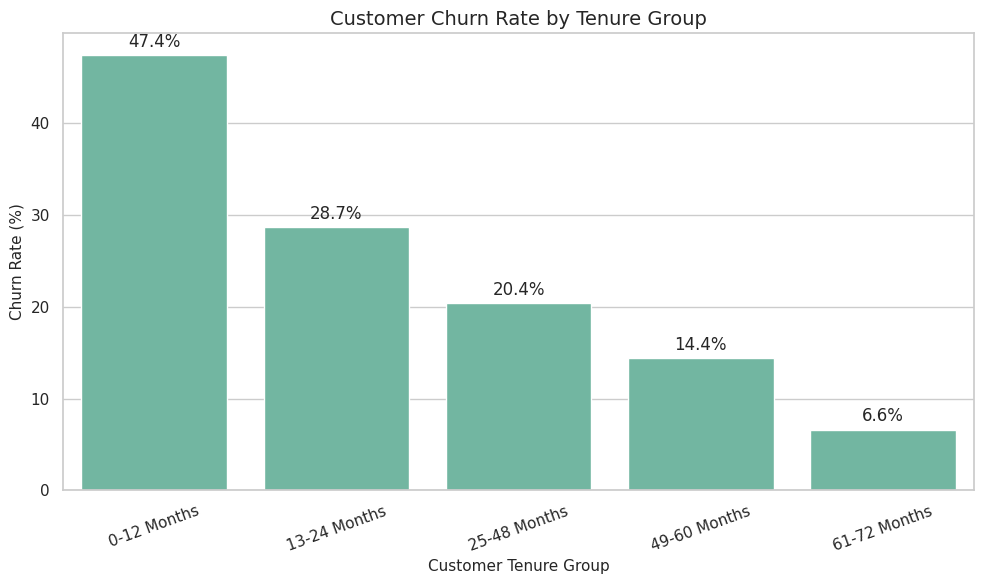

In [ ]:

# Step 18: Visualize Churn Rate by Tenure Group

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=tenure_analysis.reset_index(),
    x='TenureGroup',
    y='Churn_Rate'
)

plt.title('Customer Churn Rate by Tenure Group')
plt.xlabel('Customer Tenure Group')
plt.ylabel('Churn Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [ ]:

# Step 19: Contract Type Analysis

contract_distribution = df['Contract'].value_counts()

print("Customer Distribution by Contract Type:")
display(contract_distribution.to_frame(name='Customer Count'))

contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn']
)

print("\nContract-wise Churn Counts:")
display(contract_churn)

contract_churn_rate = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print("\nContract-wise Churn Percentage:")
display(contract_churn_rate.round(2))


Customer Distribution by Contract Type:


,Customer Count
Contract,
Month-to-month,3875
Two year,1695
One year,1473



Contract-wise Churn Counts:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48



Contract-wise Churn Percentage:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


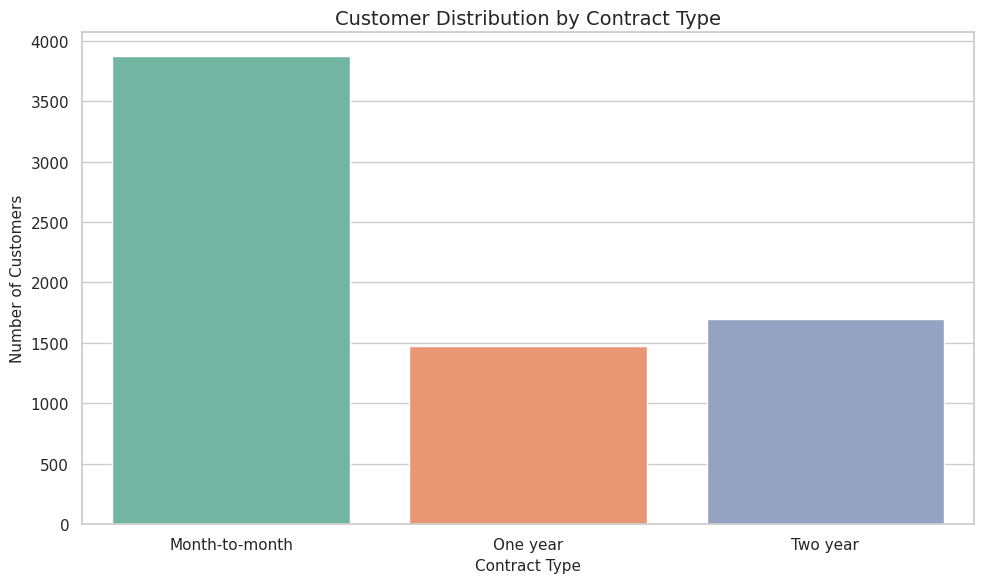

In [ ]:

# Step 20: Visualize Contract Type Distribution

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='Contract',
    hue='Contract',
    legend=False
)

plt.title('Customer Distribution by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


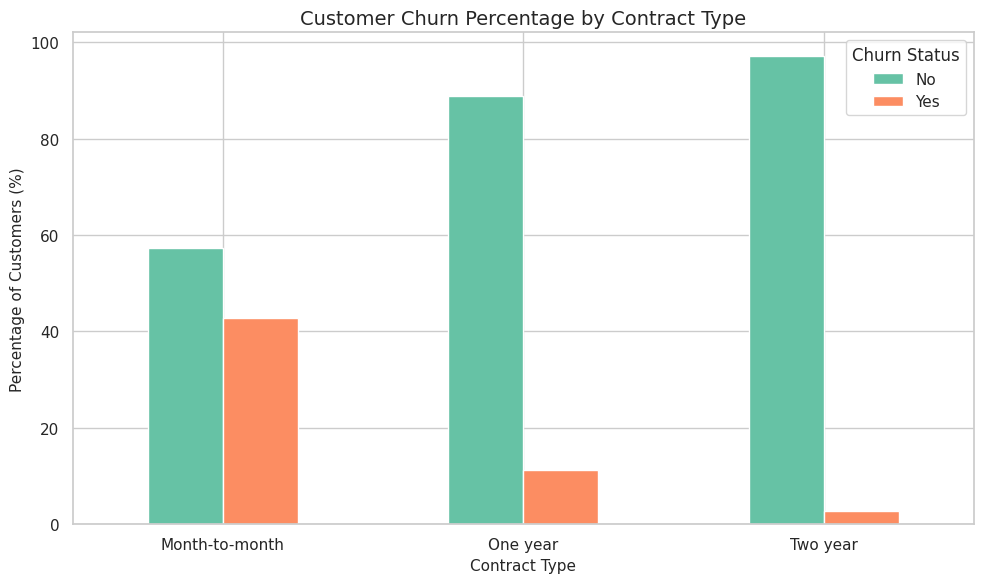

In [ ]:

# Step 21: Visualize Churn Rate by Contract Type

ax = contract_churn_rate.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Customer Churn Percentage by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Percentage of Customers (%)')

plt.xticks(rotation=0)
plt.legend(title='Churn Status')

plt.tight_layout()
plt.show()


In [ ]:

# Step 22: Payment Method Analysis

payment_distribution = df['PaymentMethod'].value_counts()

print("Customer Distribution by Payment Method:")
display(payment_distribution.to_frame(name='Customer Count'))

payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn']
)

print("\nPayment Method-wise Churn Counts:")
display(payment_churn)

payment_churn_rate = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print("\nPayment Method-wise Churn Percentage:")
display(payment_churn_rate.round(2))


Customer Distribution by Payment Method:


,Customer Count
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522



Payment Method-wise Churn Counts:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308



Payment Method-wise Churn Percentage:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


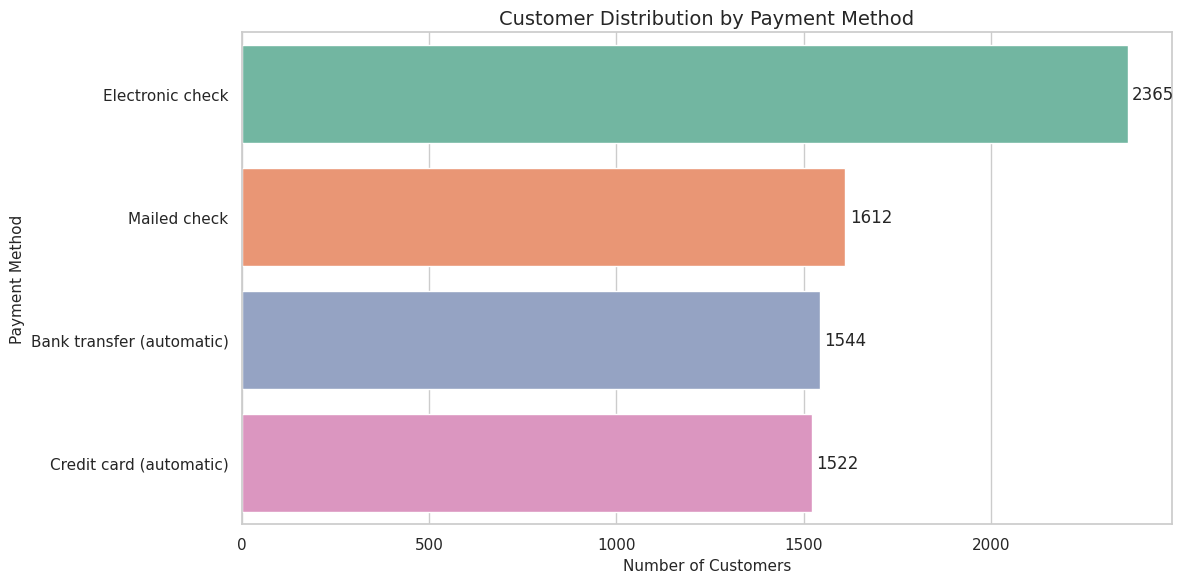

In [ ]:

# Step 23: Visualize Payment Method Distribution

plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=df,
    y='PaymentMethod',
    hue='PaymentMethod',
    legend=False,
    order=df['PaymentMethod'].value_counts().index
)

plt.title('Customer Distribution by Payment Method')
plt.xlabel('Number of Customers')
plt.ylabel('Payment Method')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


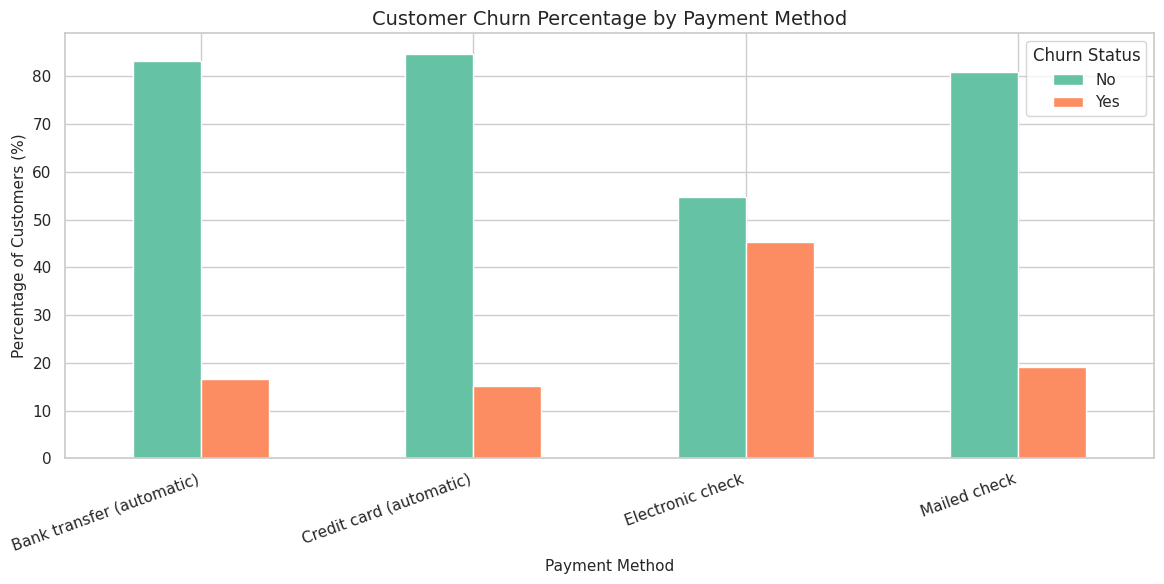

In [ ]:

# Step 24: Visualize Churn Rate by Payment Method

ax = payment_churn_rate.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Customer Churn Percentage by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Percentage of Customers (%)')

plt.xticks(rotation=20, ha='right')
plt.legend(title='Churn Status')

plt.tight_layout()
plt.show()


In [ ]:

# Step 25: Generate Overall EDA Summary

summary = pd.DataFrame({
    'Metric': [
        'Total Customers',
        'Churned Customers',
        'Retained Customers',
        'Overall Churn Rate',
        'Overall Retention Rate',
        'Average Customer Tenure',
        'Median Customer Tenure'
    ],
    'Value': [
        total_customers,
        churned_customers,
        retained_customers,
        f"{churn_rate:.2f}%",
        f"{retention_rate:.2f}%",
        f"{df['tenure'].mean():.2f} months",
        f"{df['tenure'].median():.2f} months"
    ]
})

print("FINAL CUSTOMER CHURN EDA SUMMARY")
print("=" * 45)

display(summary)

# Identify categories with the highest churn rates
print("\nKEY EDA FINDINGS")
print("=" * 45)

print(
    "Gender with highest churn rate:",
    gender_churn_rate['Yes'].idxmax()
)

print(
    "Partner status with highest churn rate:",
    partner_churn['Yes'].idxmax()
)

print(
    "Dependent status with highest churn rate:",
    dependent_churn['Yes'].idxmax()
)

print(
    "Tenure group with highest churn rate:",
    tenure_analysis['Churn_Rate'].idxmax()
)

print(
    "Contract type with highest churn rate:",
    contract_churn_rate['Yes'].idxmax()
)

print(
    "Payment method with highest churn rate:",
    payment_churn_rate['Yes'].idxmax()
)


FINAL CUSTOMER CHURN EDA SUMMARY


,Metric,Value
0,Total Customers,7043
1,Churned Customers,1869
2,Retained Customers,5174
3,Overall Churn Rate,26.54%
4,Overall Retention Rate,73.46%
5,Average Customer Tenure,32.37 months
6,Median Customer Tenure,29.00 months



KEY EDA FINDINGS
Gender with highest churn rate: Female
Partner status with highest churn rate: No
Dependent status with highest churn rate: No
Tenure group with highest churn rate: 0-12 Months
Contract type with highest churn rate: Month-to-month
Payment method with highest churn rate: Electronic check


In [ ]:

# Step 26: Export EDA Analysis Results

import os

output_folder = "Task_2_Outputs"

os.makedirs(output_folder, exist_ok=True)

# Save summary
summary.to_csv(
    f"{output_folder}/EDA_Summary.csv",
    index=False
)

# Save analysis tables
gender_churn_rate.to_csv(
    f"{output_folder}/Gender_Churn_Analysis.csv"
)

partner_churn.to_csv(
    f"{output_folder}/Partner_Churn_Analysis.csv"
)

dependent_churn.to_csv(
    f"{output_folder}/Dependent_Churn_Analysis.csv"
)

tenure_analysis.to_csv(
    f"{output_folder}/Tenure_Churn_Analysis.csv"
)

contract_churn_rate.to_csv(
    f"{output_folder}/Contract_Churn_Analysis.csv"
)

payment_churn_rate.to_csv(
    f"{output_folder}/Payment_Method_Churn_Analysis.csv"
)

print("All EDA analysis files saved successfully!")
print("Output Directory:", output_folder)


All EDA analysis files saved successfully!
Output Directory: Task_2_Outputs


In [ ]:

# Step 27: Create ZIP File and Download Outputs

import shutil
from google.colab import files

zip_filename = shutil.make_archive(
    "Task_2_Outputs",
    "zip",
    output_folder
)

print("ZIP file created successfully!")

files.download(zip_filename)


ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>